# Model Comparison

This notebook collects the test-set results saved by every model notebook
(`results/metrics/*.json`) and compares them side by side:

1. **Product classification** (11 classes): accuracy, macro-F1 (headline
   metric), weighted-F1, cross-validation score, and training time, plus
   per-class F1.
2. **Monetary relief prediction** (binary, rare positive class): ROC-AUC,
   PR-AUC compared with the positive-class prevalence, and
   precision/recall/F1 at the chosen threshold.

All models were trained on the same training split and evaluated on the
same held-out test split.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
metrics_dir = Path("../results/metrics")
figures_dir = Path("../figures")
figures_dir.mkdir(parents=True, exist_ok=True)

SHORT_LABELS = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt/Credit Mgmt",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/Personal Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan",
}

BAR_COLOR = "#2a78d6"

## 1. Load Saved Metrics

In [3]:
metric_files = sorted(metrics_dir.glob("*.json")) if metrics_dir.exists() else []

records = []

for path in metric_files:
    with open(path, encoding="utf-8") as f:
        data = json.load(f)

    # A file normally holds one model; accept a list of models as well
    for record in data if isinstance(data, list) else [data]:
        record.setdefault("model", path.stem)
        record.setdefault("display_name", record["model"])
        records.append(record)

product_records = [r for r in records if r.get("task") == "product"]
relief_records = [r for r in records if r.get("task") == "relief"]

print(f"Metric files found: {len(metric_files)}")
print(f"Product classification models: {len(product_records)}")
print(f"Monetary relief models: {len(relief_records)}")

for record in records:
    print(f"  - {record['model']:<28} task={record.get('task')}")

Metric files found: 14
Product classification models: 8
Monetary relief models: 6
  - complement_nb                task=product
  - gradient_boosting            task=product
  - knn                          task=product
  - linear_svm                   task=product
  - logistic_regression          task=product
  - mlp                          task=product
  - naive_bayes                  task=product
  - random_forest                task=product
  - relief_linear_svm            task=relief
  - relief_prevalence            task=relief
  - relief_product               task=relief
  - relief_text                  task=relief
  - relief_text_product          task=relief
  - relief_text_product_company  task=relief


## 2. Product Classification Models

Models are sorted by test macro-F1, the project's headline metric, because
it weights all 11 products equally regardless of their size.

In [4]:
PRODUCT_COLUMNS = {
    "display_name": "Model",
    "features": "Features",
    "test_accuracy": "Test Accuracy",
    "test_macro_f1": "Test Macro-F1",
    "test_weighted_f1": "Test Weighted-F1",
    "cv_macro_f1": "CV Macro-F1",
    "train_seconds": "Train Time (s)",
}

product_df = pd.DataFrame(
    [{"model": r["model"], **{key: r.get(key, np.nan) for key in PRODUCT_COLUMNS}} for r in product_records],
    columns=["model", *PRODUCT_COLUMNS]
)

if product_df.empty:
    print("No product model metrics found yet.")
else:
    product_df = product_df.sort_values("test_macro_f1", ascending=False).reset_index(drop=True)

product_table = (
    product_df.drop(columns="model")
    .rename(columns=PRODUCT_COLUMNS)
    .round({
        "Test Accuracy": 4,
        "Test Macro-F1": 4,
        "Test Weighted-F1": 4,
        "CV Macro-F1": 4,
        "Train Time (s)": 1,
    })
)

product_table

,Model,Features,Test Accuracy,Test Macro-F1,Test Weighted-F1,CV Macro-F1,Train Time (s)
0,Linear SVM,TF-IDF 1-2 grams (100k),0.8056,0.7837,0.8047,0.7770,66.1
1,Logistic Regression,TF-IDF 1-2 grams (100k),0.7978,0.7760,0.7955,0.7708,94.2
2,Multi-Layer Perceptron,TF-IDF → SVD-300,0.7770,0.7469,0.7746,0.7198,29.3
3,Gradient Boosting,TF-IDF → SVD-300,0.7650,0.7338,0.7655,0.7068,186.5
4,Multinomial Naive Bayes,TF-IDF 1-2 grams (100k),0.7494,0.7230,0.7463,0.7190,0.5
5,Complement Naive Bayes,TF-IDF 1-2 grams (100k),0.7586,0.7211,0.7514,0.7210,0.5
6,k-Nearest Neighbors,TF-IDF → SVD-300,0.7508,0.7088,0.7445,0.6905,0.2
7,Random Forest,TF-IDF → SVD-300,0.7487,0.7068,0.7431,0.6820,354.0


### Macro-F1 by Model

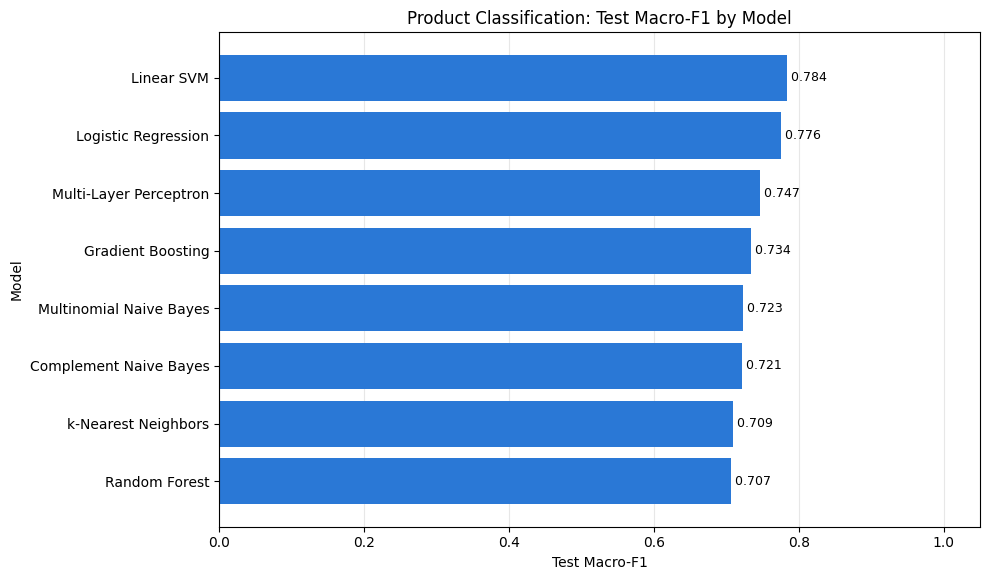

In [5]:
if product_df.empty:
    print("No product models to plot.")
else:
    plot_df = product_df.sort_values("test_macro_f1")

    fig, ax = plt.subplots(figsize=(10, 0.55 * len(plot_df) + 1.5))

    ax.barh(plot_df["display_name"], plot_df["test_macro_f1"], color=BAR_COLOR)

    for position, value in enumerate(plot_df["test_macro_f1"]):
        ax.text(value, position, f" {value:.3f}", va="center", fontsize=9)

    ax.set_xlim(0, 1.05)
    ax.set_xlabel("Test Macro-F1")
    ax.set_ylabel("Model")
    ax.set_title("Product Classification: Test Macro-F1 by Model")
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    plt.tight_layout()

    plt.savefig(
        figures_dir / "model_comparison_macro_f1.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

### Per-Class F1

The heatmap shows each model's F1-score for every product (rows follow the
macro-F1 ranking). It shows which products are hard for every model and
which ones benefit most from a stronger model.

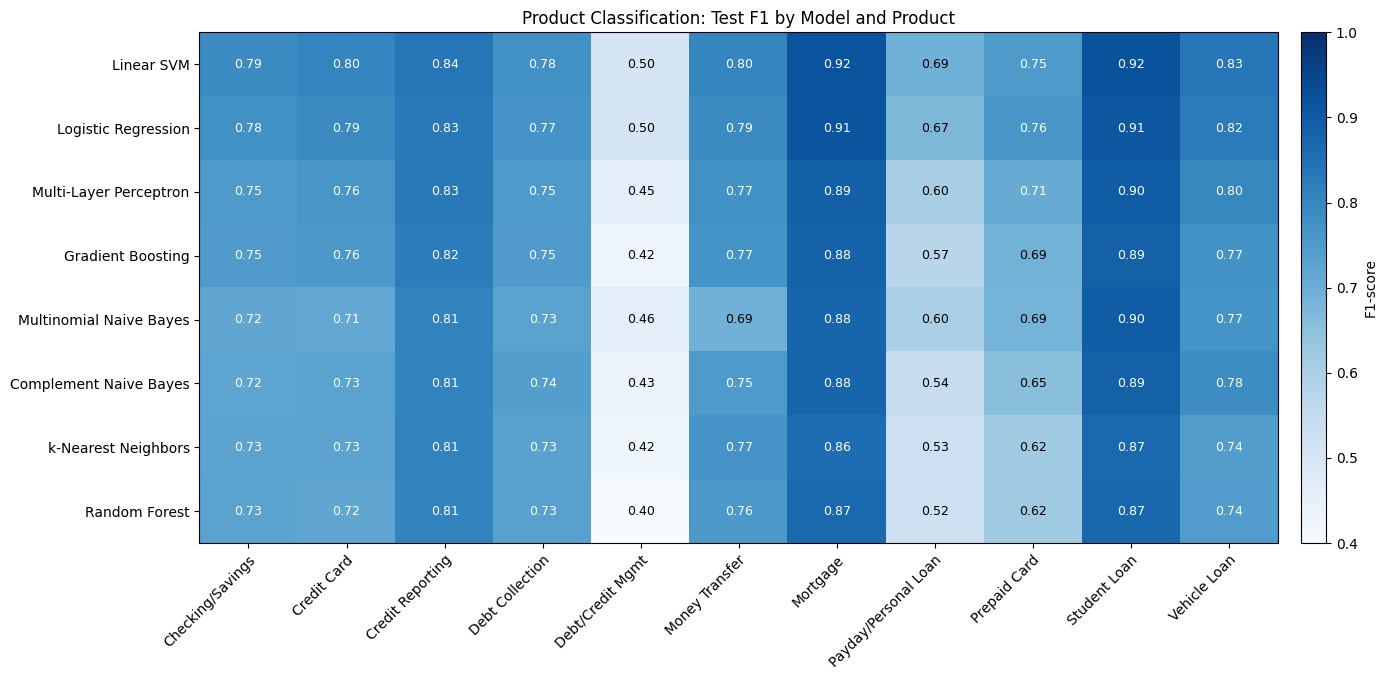

,Checking/Savings,Credit Card,Credit Reporting,Debt Collection,Debt/Credit Mgmt,Money Transfer,Mortgage,Payday/Personal Loan,Prepaid Card,Student Loan,Vehicle Loan
display_name,,,,,,,,,,,
Linear SVM,0.788,0.803,0.839,0.776,0.501,0.801,0.916,0.691,0.752,0.918,0.835
Logistic Regression,0.776,0.791,0.831,0.766,0.500,0.790,0.914,0.673,0.762,0.908,0.824
Multi-Layer Perceptron,0.753,0.762,0.829,0.752,0.453,0.775,0.889,0.604,0.706,0.895,0.798
Gradient Boosting,0.748,0.757,0.822,0.747,0.424,0.770,0.884,0.574,0.686,0.887,0.773
Multinomial Naive Bayes,0.721,0.715,0.808,0.729,0.457,0.690,0.878,0.603,0.685,0.897,0.769
Complement Naive Bayes,0.722,0.730,0.807,0.740,0.434,0.752,0.877,0.545,0.654,0.886,0.785
k-Nearest Neighbors,0.727,0.728,0.808,0.731,0.423,0.766,0.859,0.527,0.619,0.868,0.742
Random Forest,0.729,0.721,0.806,0.734,0.400,0.756,0.868,0.523,0.622,0.871,0.745


In [6]:
per_class_f1 = pd.DataFrame(
    [
        {
            SHORT_LABELS[product]: r.get("per_class", {}).get(product, {}).get("f1", np.nan)
            for product in SHORT_LABELS
        }
        for r in product_df["model"].map({r["model"]: r for r in product_records})
    ],
    index=product_df["display_name"],
    columns=list(SHORT_LABELS.values())
)

if per_class_f1.empty:
    print("No product models to plot.")
else:
    values = per_class_f1.to_numpy(dtype=float)
    finite_values = values[~np.isnan(values)]
    vmin = max(0.0, np.floor(finite_values.min() * 10) / 10) if finite_values.size else 0.0

    fig, ax = plt.subplots(figsize=(14, 0.55 * len(per_class_f1) + 2.5))

    image = ax.imshow(values, cmap="Blues", vmin=vmin, vmax=1.0, aspect="auto")

    midpoint = (vmin + 1.0) / 2
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if not np.isnan(values[i, j]):
                ax.text(
                    j, i, f"{values[i, j]:.2f}",
                    ha="center", va="center", fontsize=9,
                    color="white" if values[i, j] > midpoint else "black"
                )

    ax.set_xticks(range(values.shape[1]))
    ax.set_xticklabels(per_class_f1.columns, rotation=45, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(values.shape[0]))
    ax.set_yticklabels(per_class_f1.index)
    ax.set_title("Product Classification: Test F1 by Model and Product")

    fig.colorbar(image, ax=ax, label="F1-score", fraction=0.03, pad=0.02)
    plt.tight_layout()

    plt.savefig(
        figures_dir / "model_comparison_per_class_f1.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

per_class_f1.round(3)

In [7]:
if not per_class_f1.empty:
    print("Average F1 per product across models (hardest first):")
    print(per_class_f1.mean().sort_values().round(3).to_string())

Average F1 per product across models (hardest first):
Debt/Credit Mgmt        0.449
Payday/Personal Loan    0.593
Prepaid Card            0.686
Checking/Savings        0.746
Debt Collection         0.747
Credit Card             0.751
Money Transfer          0.762
Vehicle Loan            0.784
Credit Reporting        0.819
Mortgage                0.885
Student Loan            0.891


## 3. Monetary Relief Models

For the rare monetary relief outcome, accuracy is not informative (always
predicting "no relief" is already about 94% accurate). PR-AUC is the main
metric here: a model with no skill has a PR-AUC equal to the prevalence,
so the **PR-AUC / prevalence** ratio shows how much better than random each
model ranks the complaints.

In [8]:
RELIEF_COLUMNS = {
    "display_name": "Model",
    "features": "Features",
    "test_roc_auc": "Test ROC-AUC",
    "test_pr_auc": "Test PR-AUC",
    "prevalence": "Prevalence",
    "threshold": "Threshold",
    "test_precision": "Precision",
    "test_recall": "Recall",
    "test_f1": "F1",
    "train_seconds": "Train Time (s)",
}

relief_df = pd.DataFrame(
    [{key: r.get(key, np.nan) for key in RELIEF_COLUMNS} for r in relief_records],
    columns=list(RELIEF_COLUMNS)
)

if relief_df.empty:
    print("No monetary relief model metrics found yet.")
else:
    relief_df = relief_df.sort_values("test_pr_auc", ascending=False).reset_index(drop=True)
    relief_df.insert(
        relief_df.columns.get_loc("prevalence") + 1,
        "pr_auc_lift",
        relief_df["test_pr_auc"] / relief_df["prevalence"]
    )

relief_table = relief_df.rename(columns={**RELIEF_COLUMNS, "pr_auc_lift": "PR-AUC / Prevalence"})

relief_table.round(4)

,Model,Features,Test ROC-AUC,Test PR-AUC,Prevalence,PR-AUC / Prevalence,Threshold,Precision,Recall,F1,Train Time (s)
0,LogReg - Text + Product + Company,TF-IDF 1-2 grams (100k) + one-hot Product + on...,0.9148,0.3931,0.0564,6.9715,0.7208,0.3415,0.5906,0.4328,4.75
1,LinearSVC - Text + Product + Company,TF-IDF 1-2 grams (100k) + one-hot Product + on...,0.9138,0.3872,0.0564,6.8667,0.4461,0.3556,0.5552,0.4336,8.52
2,LogReg - Text + Product,TF-IDF 1-2 grams (100k) + one-hot Product,0.9038,0.3652,0.0564,6.4773,0.7433,0.3446,0.5243,0.4159,4.17
3,LogReg - Text,TF-IDF 1-2 grams (100k),0.9022,0.3572,0.0564,6.3359,0.7329,0.3398,0.5127,0.4087,2.05
4,LogReg - Product only,One-hot Product (11),0.8190,0.1597,0.0564,2.8316,0.7839,0.1776,0.4901,0.2607,0.07
5,Prevalence baseline (Dummy),none (class prior),0.5000,0.0564,0.0564,1.0000,0.0576,0.0564,1.0000,0.1067,0.00


## Model Comparison Summary

- **Best product model: Linear SVM** on the full TF-IDF features (1–2 grams, 100k), with **test
  macro-F1 0.784** and accuracy 0.806. Logistic Regression is close behind (0.776 / 0.798). It is the
  model used by the demo because it also gives class probabilities.
- **Sparse linear models win.** Every model trained on the 300-component SVD features scores below
  the linear models on full TF-IDF: MLP 0.747, Gradient Boosting 0.734, k-NN 0.709, Random Forest
  0.707. Compressing to 300 components keeps only about 20% of the TF-IDF variance and costs a linear
  model about 0.05 macro-F1 (see `03_dimensionality_reduction_clustering.ipynb`), and the nonlinear
  models do not win that back. Tuned Naive Bayes (0.723 / 0.721) is a strong, very fast baseline.
  Tuning and the richer bigram features alone lift it from the team's original 0.695.
- **Training time** (final fit on the full training set): Naive Bayes trains in under a second, the linear
  models in about 1–1.5 minutes, gradient boosting in about 3 minutes, and the Random Forest is the
  slowest at about 6 minutes.
- **Hardest products:** *Debt or credit management* (average F1 0.45 across models), *Payday /
  personal loan* (0.59) and *Prepaid card* (0.69): small classes whose complaints overlap with debt
  collection, credit cards and checking accounts. *Student loan* (0.89) and *Mortgage* (0.89) are
  easiest, because their vocabulary and servicer names are distinctive.
- **Monetary relief:** with only 5.6% positives, Logistic Regression on text + product + company
  reaches **PR-AUC 0.393** (7.0× the prevalence) and ROC-AUC 0.915. Text alone (the demo model) gets
  PR-AUC 0.357, and product alone only 0.160, so the narrative carries most of the signal. At the
  threshold chosen on the training folds, the best model catches 59% of monetary-relief complaints
  with 34% precision.